## 1. Fase 1 - Comprensión del negocio

### 1.1 Contexto del problema
Las empresas de telecomunicaciones pierden ingresos cuando un cliente cancela su servicio. Detectar clientes con alta probabilidad de churn permite diseñar campañas de retención más efectivas y reducir la pérdida de ingresos.

### 1.2 Objetivo general
Construir un modelo de **clasificación** que estime la probabilidad de churn de cada cliente para apoyar decisiones de retención.

### 1.3 Objetivos específicos
- Identificar variables que se asocian al abandono.
- Estimar el riesgo de churn por cliente.
- Proponer acciones de negocio según segmentos de riesgo (alto, medio, bajo).

Alumnos : Tabatha Gamboa - Fabian Parraguez

### 1.4 Criterios de éxito

**Éxito de negocio:**
- Disminuir la tasa de churn en campañas piloto de retención.
- Priorizar clientes con mayor riesgo para optimizar presupuesto comercial.

**Éxito técnico (inicial):**
- `Recall` de la clase churn mayor o igual a 0.70 (detectar la mayor cantidad posible de clientes en riesgo).
- `ROC-AUC` mayor o igual a 0.80 como referencia de capacidad discriminante.

### 1.5 Supuestos y restricciones
- Se asume que el dataset representa adecuadamente la población actual de clientes.
- No se consideran costos reales de campaña en esta primera entrega.
- El target es binario (`Churn`: Yes/No).
- Posible desbalance de clases que deberá tratarse en iteraciones futuras.

### 1.6 Plan de iteraciones (mínimo 3 para la entrega final)
1. **Iteración 1 (baseline):** limpieza básica + modelo base (por ejemplo, regresión logística).
2. **Iteración 2 (mejora de datos/modelo):** tratamiento de desbalance, ingeniería de variables, ajuste de hiperparámetros.
3. **Iteración 3 (optimización y validación):** comparación de modelos (árboles/ensambles), calibración de umbral y evaluación de impacto de negocio.

En esta primera entrega se documentan únicamente las fases 1 y 2 de CRISP-DM.

## 2. Fase 2 - Comprensión de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
# Carga de datos
df = pd.read_csv('Telco_Customer_Churn_Dataset.csv')

print('Dimensiones:', df.shape)
print(' Columnas:')
print(df.columns.tolist())

df.head()

Dimensiones: (7043, 21)
 Columnas:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Estructura y tipos de datos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Calidad de datos: valores faltantes y duplicados
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

print('Valores faltantes por columna (solo > 0):')
print(missing if len(missing) > 0 else 'No se detectan nulos explícitos.')

print(' Duplicados totales:', df.duplicated().sum())

Valores faltantes por columna (solo > 0):
No se detectan nulos explícitos.
 Duplicados totales: 0


Frecuencia de Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
 Porcentaje de Churn:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


C:\Users\fabia\AppData\Local\Temp\ipykernel_19592\3090817631.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


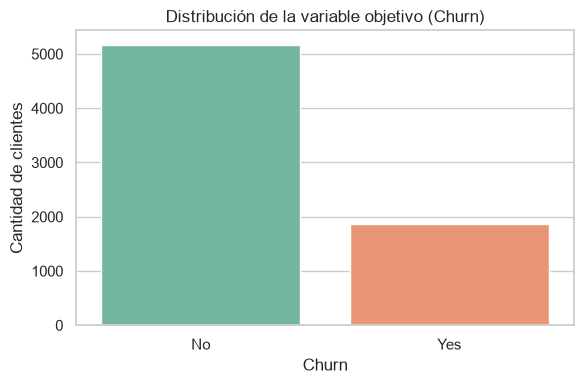

In [5]:
# Revisión rápida de la variable objetivo
target_dist = df['Churn'].value_counts(dropna=False)
target_pct = df['Churn'].value_counts(normalize=True, dropna=False) * 100

print('Frecuencia de Churn:')
print(target_dist)
print(' Porcentaje de Churn:')
print(target_pct.round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Distribución de la variable objetivo (Churn)')
plt.xlabel('Churn')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

In [6]:
# Resumen descriptivo de variables numéricas
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


### 2.1 Hallazgos iniciales de la fase de comprensión de datos
- El dataset contiene **7043 registros** y **21 columnas**.
- El problema es de **clasificación binaria** (`Churn`).
- Se requiere revisar con mayor detalle variables categóricas y codificación para el modelado.
- Es probable que exista **desbalance de clases** en la variable objetivo (a validar con los porcentajes mostrados).
- En la siguiente fase (preparación de datos) se debe validar si existen faltantes no explícitos (por ejemplo, espacios en blanco en columnas tipo texto).

## Checklist de primera entrega (CRISP-DM Fase 1 y 2)
- [x] Definición del problema de negocio
- [x] Objetivos y criterios de éxito
- [x] Restricciones y plan de iteraciones
- [x] Carga y descripción de datos
- [x] Revisión inicial de calidad de datos
- [x] Exploración inicial de la variable objetivo